<a href="https://colab.research.google.com/github/araujoluigif/cp5-statistical-computing/blob/main/CP5_Statistical_Computing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Total de vinhos: 178
Nulos em Alcool: 0 | Nulos em Acido_Malico: 0
Número de classes (Sturges): 9


,fi (freq. absoluta),fri (freq. relativa %),Fi (freq. acumulada),Fri (freq. rel. acumulada %)
Classe,,,,
"(11.026, 11.452]",3,1.69,3,1.69
"(11.452, 11.874]",15,8.43,18,10.12
"(11.874, 12.297]",23,12.92,41,23.04
"(12.297, 12.719]",28,15.73,69,38.77
"(12.719, 13.141]",28,15.73,97,54.50
"(13.141, 13.563]",30,16.85,127,71.35
"(13.563, 13.986]",29,16.29,156,87.64
"(13.986, 14.408]",20,11.24,176,98.88
"(14.408, 14.83]",2,1.12,178,100.00


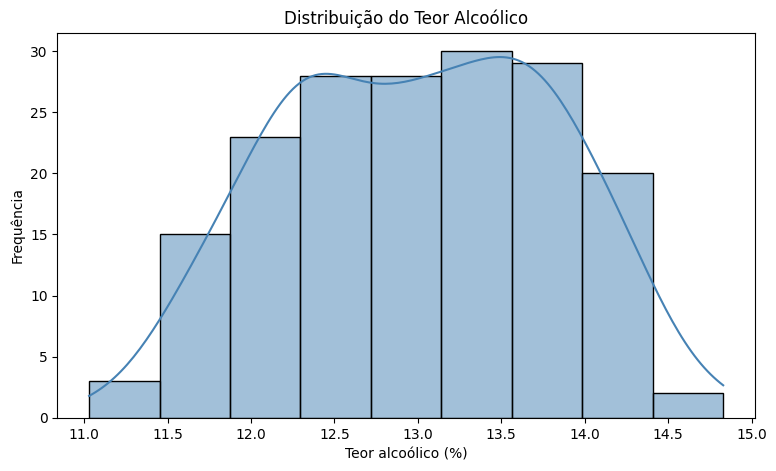

Número de classes (Sturges): 9


,fi (freq. absoluta),fri (freq. relativa %),Fi (freq. acumulada),Fri (freq. rel. acumulada %)
Classe,,,,
"(0.735, 1.302]",21,11.80,21,11.80
"(1.302, 1.864]",68,38.20,89,50.00
"(1.864, 2.427]",25,14.04,114,64.04
"(2.427, 2.989]",16,8.99,130,73.03
"(2.989, 3.551]",16,8.99,146,82.02
"(3.551, 4.113]",17,9.55,163,91.57
"(4.113, 4.676]",8,4.49,171,96.06
"(4.676, 5.238]",4,2.25,175,98.31
"(5.238, 5.8]",3,1.69,178,100.00


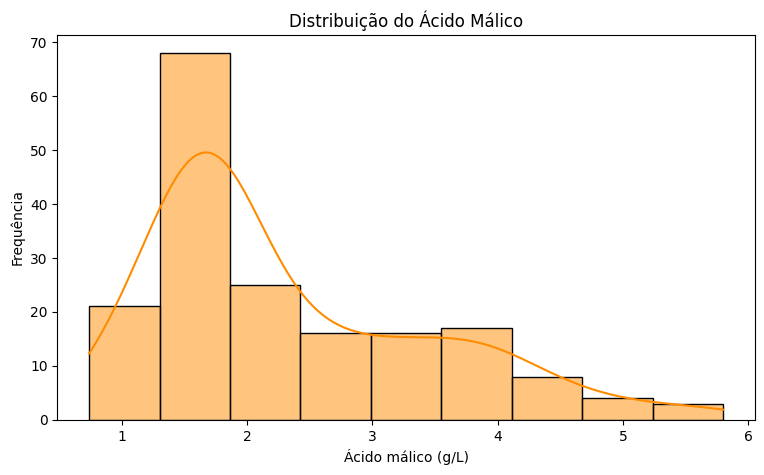

In [1]:
"""Parte 1 – Statistical Computing with Python: Análise Exploratória do Dataset Wines

Variáveis quantitativas escolhidas:
- Alcool: teor alcoólico do vinho (%)
- Acido_Malico: concentração de ácido málico, ligada à acidez do vinho (g/L)

Escolhemos essas duas porque são características fáceis de interpretar e se comportam de formas bem diferentes: uma é praticamente simétrica e a outra é assimétrica. Isso enriquece a comparação.

Integrantes:
Luigi Francisco RM:571204
Breno Filipe RM:571824
Igor Cypriano RM:570353
Diogo Lopes RM:570732
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

url = "https://gist.githubusercontent.com/tijptjik/9408623/raw/b237fa5848349a14a14e5d4107dc7897c21951f5/wine.csv"
df = pd.read_csv(url)

df.columns = ['Classe', 'Alcool', 'Acido_Malico', 'Cinzas', 'Alcalinidade_Cinzas',
              'Magnesio', 'Fenois_Totais', 'Flavonoides', 'Fenois_Nao_Flavonoides',
              'Proantocianinas', 'Intensidade_Cor', 'Matiz', 'OD280_OD315', 'Prolina']

alcool = df['Alcool']
acido = df['Acido_Malico']

print(f"Total de vinhos: {len(df)}")
print(f"Nulos em Alcool: {alcool.isnull().sum()} | Nulos em Acido_Malico: {acido.isnull().sum()}")

# Função que monta a tabela de distribuição de frequências para variável contínua.
# Número de classes pela Regra de Sturges: k = 1 + 3,322 * log10(n)
# Com n = 178, k ≈ 8,47 → arredondamos para cima: 9 classes.
def tabela_frequencia(serie):
    n = len(serie)
    k = int(np.ceil(1 + 3.322 * np.log10(n)))
    classes = pd.cut(serie, bins=k)
    tabela = pd.DataFrame({
        'fi (freq. absoluta)': classes.value_counts().sort_index()
    })
    tabela['fri (freq. relativa %)'] = (tabela['fi (freq. absoluta)'] / n * 100).round(2)
    tabela['Fi (freq. acumulada)'] = tabela['fi (freq. absoluta)'].cumsum()
    tabela['Fri (freq. rel. acumulada %)'] = tabela['fri (freq. relativa %)'].cumsum().round(2)
    tabela.index.name = 'Classe'
    return tabela, k

# ---------- a) Tabela de frequências e gráfico: ALCOOL ----------
tab_alcool, k = tabela_frequencia(alcool)
print(f"Número de classes (Sturges): {k}")
display(tab_alcool)

plt.figure(figsize=(9, 5))
sns.histplot(alcool, bins=k, kde=True, color='steelblue')
plt.title('Distribuição do Teor Alcoólico')
plt.xlabel('Teor alcoólico (%)')
plt.ylabel('Frequência')
plt.show()

# Interpretação:
# - O teor alcoólico varia de 11,03% a 14,83%.
# - As frequências se concentram no meio: as classes entre ~12,3% e ~14,0%
#   reúnem cerca de 65% dos vinhos.
# - As pontas têm poucos vinhos (3 abaixo de ~11,45% e só 2 acima de ~14,4%).
# - O histograma tem formato aproximadamente simétrico, de "sino" achatado,
#   sem valores extremos isolados.

# ---------- a) Tabela de frequências e gráfico: ACIDO MALICO ----------
tab_acido, k = tabela_frequencia(acido)
print(f"Número de classes (Sturges): {k}")
display(tab_acido)

plt.figure(figsize=(9, 5))
sns.histplot(acido, bins=k, kde=True, color='darkorange')
plt.title('Distribuição do Ácido Málico')
plt.xlabel('Ácido málico (g/L)')
plt.ylabel('Frequência')
plt.show()

# Interpretação:
# - O ácido málico varia de 0,74 a 5,80.
# - A distribuição é bem diferente da do álcool: há um pico forte na classe
#   de ~1,30 a ~1,86 (68 vinhos, cerca de 38% do total).
# - À direita, a frequência cai aos poucos, formando uma "cauda" longa até 5,8.
# - Isso indica assimetria positiva (à direita): a maioria dos vinhos tem
#   acidez baixa, e um grupo menor tem acidez bem mais alta.


,Alcool,Acido_Malico
Média,13.000618,2.336348
Mediana,13.05,1.865
Moda,"12.37, 13.05",1.73
Mínimo,11.03,0.74
Máximo,14.83,5.8
Amplitude,3.8,5.06
Variância,0.659062,1.248015
Desvio padrão,0.811827,1.117146
Coef. de variação (%),6.244523,47.815905
Q1 (25%),12.3625,1.6025


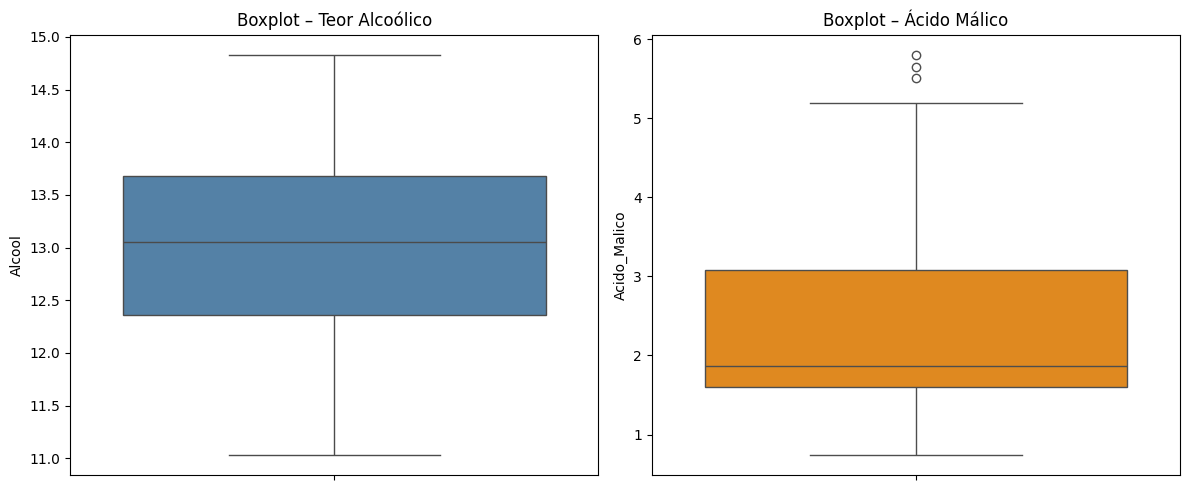

In [2]:
# ---------- b) Medidas de tendência central, dispersão e separatrizes ----------
def medidas_descritivas(serie):
    q1, q2, q3 = serie.quantile([0.25, 0.50, 0.75])
    return pd.Series({
        # Tendência central
        'Média': serie.mean(),
        'Mediana': serie.median(),
        'Moda': ', '.join(map(str, serie.mode().tolist())),
        # Dispersão
        'Mínimo': serie.min(),
        'Máximo': serie.max(),
        'Amplitude': serie.max() - serie.min(),
        'Variância': serie.var(),
        'Desvio padrão': serie.std(),
        'Coef. de variação (%)': serie.std() / serie.mean() * 100,
        # Separatrizes
        'Q1 (25%)': q1,
        'Q2 (50%)': q2,
        'Q3 (75%)': q3,
        'Amplitude interquartil (IQR)': q3 - q1,
        # Forma
        'Assimetria': serie.skew(),
    })

resumo = pd.DataFrame({
    'Alcool': medidas_descritivas(alcool),
    'Acido_Malico': medidas_descritivas(acido)
})
display(resumo)

# Boxplots para visualizar quartis e possíveis outliers
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(y=alcool, ax=ax[0], color='steelblue')
ax[0].set_title('Boxplot – Teor Alcoólico')
sns.boxplot(y=acido, ax=ax[1], color='darkorange')
ax[1].set_title('Boxplot – Ácido Málico')
plt.tight_layout()
plt.show()

# Interpretação – ALCOOL:
# - Tendência central: média (13,00%) e mediana (13,05%) quase iguais, o que confirma a
#   simetria vista no histograma. Há duas modas (12,37 e 13,05), mas como a variável é
#   contínua, a moda pontual pouco informa; a classe modal fica entre ~13,1% e ~13,6%.
# - Dispersão: desvio padrão de 0,81 e coeficiente de variação de ~6,2%. Os vinhos
#   são bem homogêneos em teor alcoólico.
# - Quartis: 25% dos vinhos têm até 12,36%, 50% até 13,05% e 75% até 13,68%.
#   A metade central dos dados está num intervalo estreito (IQR = 1,32).
# - Assimetria ≈ -0,05 (praticamente zero) e nenhum outlier no boxplot.

# Interpretação – ACIDO MALICO:
# - Tendência central: média (2,34) bem maior que a mediana (1,87). Isso acontece porque
#   os poucos vinhos muito ácidos "puxam" a média para cima. Aqui, a mediana representa
#   melhor o vinho típico.
# - Dispersão: desvio padrão de 1,12 e coeficiente de variação de ~47,8%. A variabilidade
#   é alta, quase 8 vezes maior (em termos relativos) que a do álcool.
# - Quartis: Q1 = 1,60, Q2 = 1,87 e Q3 = 3,08. A distância de Q2 a Q3 (1,22) é muito
#   maior que de Q1 a Q2 (0,26), outro sinal da cauda à direita.
# - Assimetria ≈ 1,04 (positiva e forte). O boxplot mostra 3 outliers acima do limite
#   superior (Q3 + 1,5·IQR ≈ 5,30).


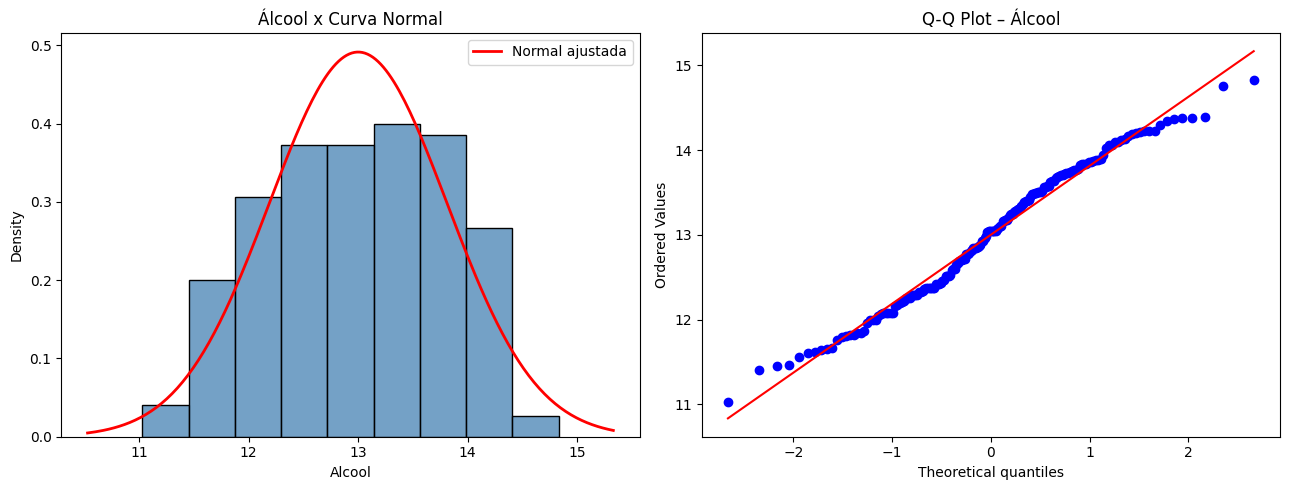

Shapiro-Wilk: estatística = 0.9818, p-valor = 0.0200
P(Álcool > 14%)  → Normal: 10.92% | Real nos dados: 12.36%
P(12% < Álcool < 14%) → Normal: 78.20% | Real nos dados: 75.28%


In [3]:
# ---------- c) Distribuição de probabilidade: ALCOOL ----------
# Como o álcool é simétrico e em forma de sino, testamos a Distribuição Normal.
media_alc, dp_alc = alcool.mean(), alcool.std()

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(alcool, bins=9, stat='density', color='steelblue', ax=ax[0])
x = np.linspace(alcool.min() - 0.5, alcool.max() + 0.5, 200)
ax[0].plot(x, stats.norm.pdf(x, media_alc, dp_alc), 'r', lw=2, label='Normal ajustada')
ax[0].set_title('Álcool x Curva Normal')
ax[0].legend()
stats.probplot(alcool, dist='norm', plot=ax[1])
ax[1].set_title('Q-Q Plot – Álcool')
plt.tight_layout()
plt.show()

stat, p = stats.shapiro(alcool)
print(f"Shapiro-Wilk: estatística = {stat:.4f}, p-valor = {p:.4f}")

# Interpretação do ajuste:
# - Visualmente, a curva normal acompanha bem o histograma, e no Q-Q plot os pontos ficam
#   próximos da reta, desviando um pouco só nas pontas.
# - O Shapiro-Wilk dá p ≈ 0,02, que rejeita a normalidade estrita a 5%. Isso acontece porque
#   a distribuição é mais "achatada" que a normal (curtose negativa), e o teste é sensível
#   com 178 observações.
# - Ainda assim, a normal é uma aproximação razoável para os cálculos abaixo, e comparamos
#   cada resultado com a proporção real dos dados.

# Cálculo 1: probabilidade de um vinho ter mais de 14% de álcool
p1 = 1 - stats.norm.cdf(14, media_alc, dp_alc)
real1 = (alcool > 14).mean()
print(f"P(Álcool > 14%)  → Normal: {p1:.2%} | Real nos dados: {real1:.2%}")

# Cálculo 2: probabilidade de um vinho ter entre 12% e 14% de álcool
p2 = stats.norm.cdf(14, media_alc, dp_alc) - stats.norm.cdf(12, media_alc, dp_alc)
real2 = ((alcool > 12) & (alcool < 14)).mean()
print(f"P(12% < Álcool < 14%) → Normal: {p2:.2%} | Real nos dados: {real2:.2%}")

# Interpretação:
# - Cerca de 10,9% dos vinhos devem ter mais de 14% de álcool pela normal; nos dados são 12,4%.
# - Cerca de 78,2% devem ficar entre 12% e 14%; nos dados são 75,3%.
# - Os valores teóricos ficam a menos de 3 pontos percentuais dos reais, então o modelo
#   normal descreve bem o teor alcoólico.


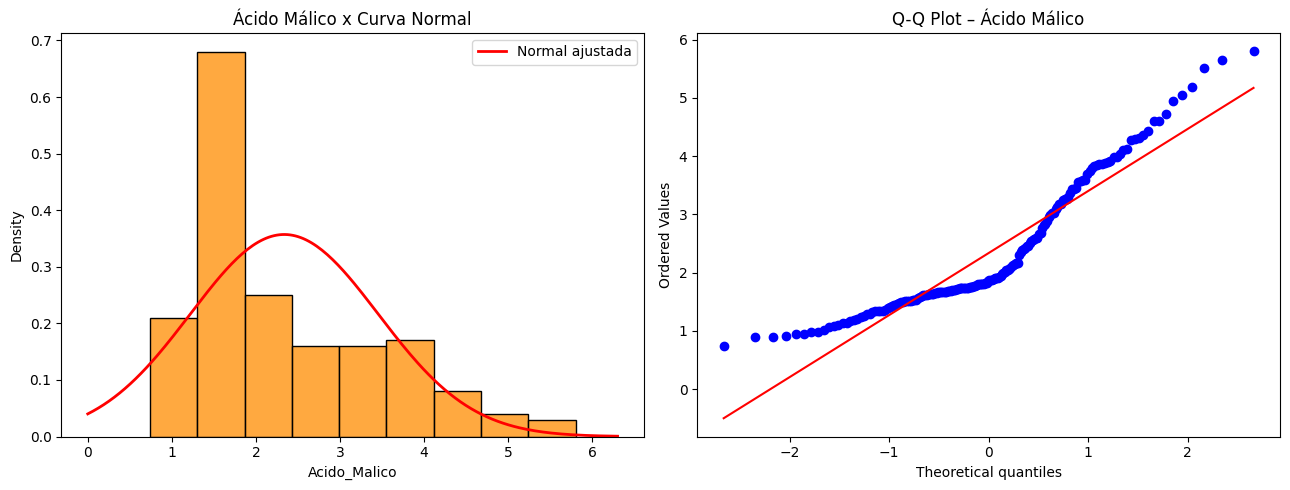

Shapiro-Wilk: estatística = 0.8888, p-valor = 2.95e-10
P(Ácido > 3) → Empírica: 26.40% | Normal: 27.62%
P(Ácido < 2) → Empírica: 56.18% | Normal: 38.17%


In [4]:
# ---------- c) Distribuição de probabilidade: ACIDO MALICO ----------
# Aqui a variável é assimétrica, então a Normal não deve servir. Vamos verificar.
media_ac, dp_ac = acido.mean(), acido.std()

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(acido, bins=9, stat='density', color='darkorange', ax=ax[0])
x = np.linspace(0, acido.max() + 0.5, 200)
ax[0].plot(x, stats.norm.pdf(x, media_ac, dp_ac), 'r', lw=2, label='Normal ajustada')
ax[0].set_title('Ácido Málico x Curva Normal')
ax[0].legend()
stats.probplot(acido, dist='norm', plot=ax[1])
ax[1].set_title('Q-Q Plot – Ácido Málico')
plt.tight_layout()
plt.show()

stat, p = stats.shapiro(acido)
print(f"Shapiro-Wilk: estatística = {stat:.4f}, p-valor = {p:.2e}")

# Interpretação do ajuste:
# - A curva normal não acompanha o histograma: ela "erra" o pico em ~1,6 e ainda atribui
#   probabilidade a valores negativos, o que é impossível para uma concentração.
# - No Q-Q plot, os pontos formam uma curva, típico de assimetria à direita.
# - O Shapiro-Wilk dá p ≈ 0,0000000003, e a normalidade é fortemente rejeitada.
# - Por isso, usamos a distribuição empírica (as proporções observadas nos dados) como
#   referência e mostramos quanto a Normal erraria.

# Cálculo 1: probabilidade de um vinho ter ácido málico acima de 3 (vinho "muito ácido")
p1_normal = 1 - stats.norm.cdf(3, media_ac, dp_ac)
p1_real = (acido > 3).mean()
print(f"P(Ácido > 3) → Empírica: {p1_real:.2%} | Normal: {p1_normal:.2%}")

# Cálculo 2: probabilidade de um vinho ter ácido málico abaixo de 2 (vinho pouco ácido)
p2_normal = stats.norm.cdf(2, media_ac, dp_ac)
p2_real = (acido < 2).mean()
print(f"P(Ácido < 2) → Empírica: {p2_real:.2%} | Normal: {p2_normal:.2%}")

# Interpretação:
# - 26,4% dos vinhos têm ácido málico acima de 3; a Normal estimaria 27,6% (erro pequeno aqui).
# - 56,2% dos vinhos têm ácido málico abaixo de 2, mas a Normal estimaria só ~38%.
#   Ela subestima muito a região onde os dados se concentram.
# - Conclusão: para variáveis assimétricas como o ácido málico, a Normal não é adequada.
#   A distribuição empírica é a referência mais confiável.


## Conclusão

| | Álcool | Ácido Málico |
|---|---|---|
| Forma | Simétrica | Assimétrica à direita |
| Média x Mediana | Praticamente iguais (13,00 x 13,05) | Média > mediana (2,34 x 1,87) |
| Variabilidade (CV) | Baixa (~6%) | Alta (~48%) |
| Outliers | Nenhum | 3 acima de 5,30 |
| Distribuição | Aproximadamente Normal | Não Normal (usada a empírica) |

O teor alcoólico dos vinhos é homogêneo e a distribuição Normal aproxima as probabilidades calculadas, embora o teste rejeite a normalidade estrita.
O ácido málico é muito mais variável: a maioria dos vinhos tem acidez baixa,
mas existe um grupo menor de vinhos bem mais ácidos.
